In [202]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [203]:
# Load the data
df = pd.read_csv('../csv/competitions.csv')

df.head()

,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code,confederation,url
0,CIT,italy-cup,italy-cup,domestic_cup,domestic_cup,75,Italy,IT1,europa,https://www.transfermarkt.co.uk/italy-cup/star...
1,NLSC,johan-cruijff-schaal,johan-cruijff-schaal,domestic_super_cup,other,122,Netherlands,NL1,europa,https://www.transfermarkt.co.uk/johan-cruijff-...
2,GRP,kypello-elladas,kypello-elladas,domestic_cup,domestic_cup,56,Greece,GR1,europa,https://www.transfermarkt.co.uk/kypello-ellada...
3,POSU,supertaca-candido-de-oliveira,supertaca-candido-de-oliveira,domestic_super_cup,other,136,Portugal,PO1,europa,https://www.transfermarkt.co.uk/supertaca-cand...
4,RUSS,russian-super-cup,russian-super-cup,domestic_super_cup,other,141,Russia,RU1,europa,https://www.transfermarkt.co.uk/russian-super-...


## Data Exploration
The dataset contains 10 columns and 43 rowns. The columns are:
- `competition_id`: The unique identifier for the competition
- `competition_code`: The code for the competition
- `competition_name`: The name of the competition
- `sub_type`: The competition subtype, it indicates if the competition is a league, cup, etc.
- `type`: The competition type, it indicates if the competition is domestic, international, etc.
- `country_id`: The unique identifier for the country
- `country_name`: The name of the country in which the competition takes place
- `domestic_league_code`: The code for the domestic league
- `confederation`: The confederation to which the competition belongs
- `url`: connection to more information about the competition

## Data Cleaning

In [204]:
#check for duplicates
print("Duplicated rows: ", df.duplicated().sum())

#check for missing values
df.isnull().sum()

Duplicated rows:  0


competition_id          0
competition_code        0
name                    0
sub_type                0
type                    0
country_id              0
country_name            7
domestic_league_code    7
confederation           0
url                     0
dtype: int64

The missing values are related to `country_name` and `domestic_league_code` we are going to handle this missing values.

In [205]:
#check for unique values in the dataset
unique_values = df.nunique()
print(unique_values)
print("confederation: ", df['confederation'].unique())

competition_id          43
competition_code        42
name                    42
sub_type                11
type                     4
country_id              15
country_name            14
domestic_league_code    14
confederation            1
url                     43
dtype: int64
confederation:  ['europa']


The column `confederation` has only one unique value, we are going to drop this column and same for the column `url`. <br>
Since the column `domestic_league_code` has missing values and we for sure know that the confederation is 'europe' we are going to fill this values with 'EU'

In [206]:
df.loc[df['country_name'].isnull(), 'country_name'] = 'unknown'
df.loc[df['domestic_league_code'].isnull(), 'domestic_league_code'] = 'EU'

null_values = df.isnull().sum()
total_missing = null_values.sum()

print("Total missing values: ", total_missing)

# Drop the columns confederation and url that aren't usefull for the analysis
df.drop(['confederation', 'url'], axis=1, inplace=True)

#converting the columns to uppercase and replacing characters for better visualization and usage
df['competition_code'] = df['competition_code'].str.upper()
df['competition_code'] = df['competition_code'].str.replace('-', ' ')

df['name'] = df['name'].str.upper()
df['name'] = df['name'].str.replace('-', ' ')

df['sub_type'] = df['sub_type'].str.upper()
df['sub_type'] = df['sub_type'].str.replace('_', ' ')

df['type'] = df['type'].str.upper()
df['type'] = df['type'].str.replace('_', ' ')
df

Total missing values:  0


,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code
0,CIT,ITALY CUP,ITALY CUP,DOMESTIC CUP,DOMESTIC CUP,75,Italy,IT1
1,NLSC,JOHAN CRUIJFF SCHAAL,JOHAN CRUIJFF SCHAAL,DOMESTIC SUPER CUP,OTHER,122,Netherlands,NL1
2,GRP,KYPELLO ELLADAS,KYPELLO ELLADAS,DOMESTIC CUP,DOMESTIC CUP,56,Greece,GR1
3,POSU,SUPERTACA CANDIDO DE OLIVEIRA,SUPERTACA CANDIDO DE OLIVEIRA,DOMESTIC SUPER CUP,OTHER,136,Portugal,PO1
4,RUSS,RUSSIAN SUPER CUP,RUSSIAN SUPER CUP,DOMESTIC SUPER CUP,OTHER,141,Russia,RU1
5,SUC,SUPERCOPA,SUPERCOPA,DOMESTIC SUPER CUP,OTHER,157,Spain,ES1
6,USC,UEFA SUPER CUP,UEFA SUPER CUP,UEFA SUPER CUP,OTHER,-1,unknown,EU
7,DK1,SUPERLIGAEN,SUPERLIGAEN,FIRST TIER,DOMESTIC LEAGUE,39,Denmark,DK1
8,EL,EUROPA LEAGUE,EUROPA LEAGUE,EUROPA LEAGUE,INTERNATIONAL CUP,-1,unknown,EU
9,ES1,LALIGA,LALIGA,FIRST TIER,DOMESTIC LEAGUE,157,Spain,ES1


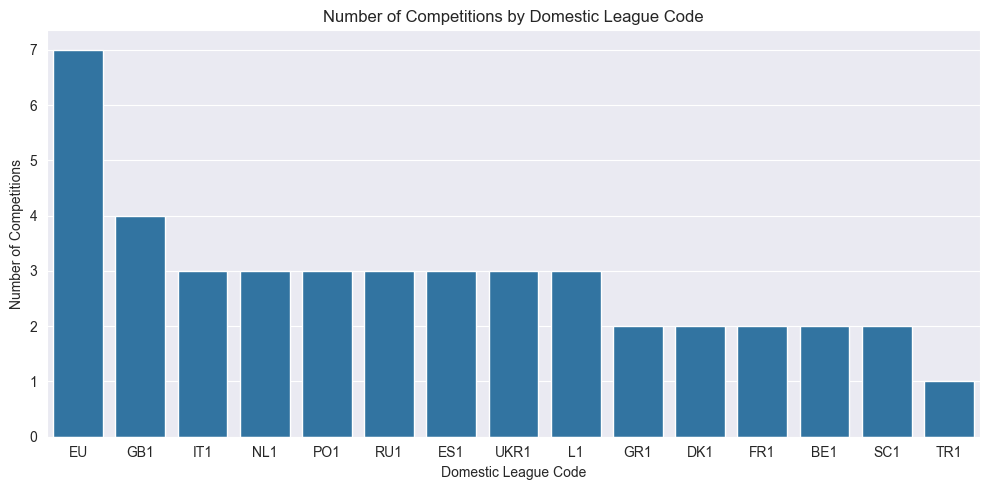

In [207]:
#counting the number of competitions by domestic league code
competition_count = df['domestic_league_code'].value_counts().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='domestic_league_code', y='count', data=competition_count)
plt.title('Number of Competitions by Domestic League Code')
plt.xlabel('Domestic League Code')
plt.ylabel('Number of Competitions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Data Visualization
The plot above shows the number of competitions by domestic league code. 
- Dominance of 'EU' Code: The code 'EU' leads with the highest number of competitions. However, it's important to note that this code was used as a placeholder for missing values. Its prevalence may reflect competitions that span multiple countries or leagues without a specific domestic affiliation, or it could indicate areas where further data collection is needed.

- Second-Highest: 'GB1': The second-highest number of competitions is associated with the 'GB1' code, which represents top-tier competitions in Great Britain. This highlights the region's strong football culture, which hosts multiple domestic and international tournaments.

- Smallest Representation: 'TR1': At the other end, the code 'TR1', representing Turkey's top league, has the least number of competitions. This may indicate a more concentrated football structure in Turkey, with fewer leagues or competitions relative to other regions.

The variation in the number of competitions across league codes could be influenced by factors such as the size of the country, the structure of its football leagues, and the inclusion of both domestic and international tournaments. 

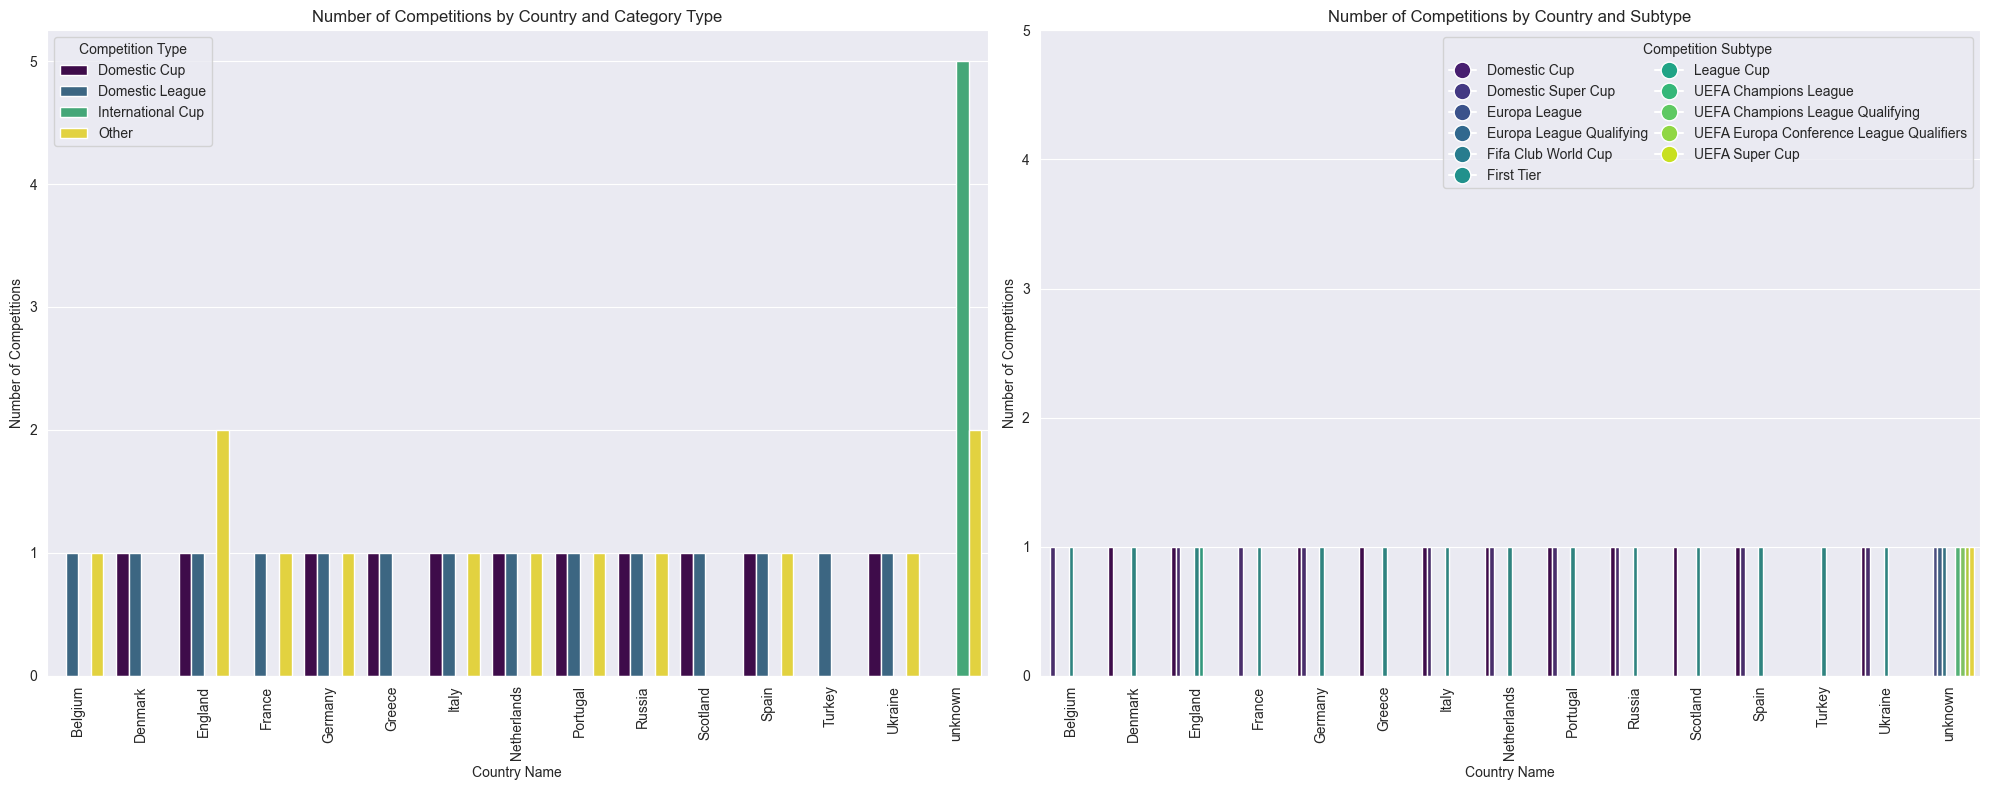

In [208]:
# Convert the column type to category for visualization
df['category_type'] = df['type'].astype('category').cat.codes

# Group by 'country_name' and 'category_type' to count occurrences
competition_by_country_type = df.groupby(['country_name', 'category_type']).size().reset_index(name='count')

# Convert the column 'sub_type' to category and get its codes
df['category_sub_type'] = df['sub_type'].astype('category').cat.codes

# Group by 'country_name' and 'category_sub_type' to count occurrences
competition_by_country_subtype = df.groupby(['country_name', 'category_sub_type']).size().reset_index(name='count')

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot for Category Type
bar_plot_1 = sns.barplot(x='country_name', y='count', hue='category_type', data=competition_by_country_type, palette='viridis', ax=axes[0])

# Customize the first plot
axes[0].set_title('Number of Competitions by Country and Category Type')
axes[0].set_xlabel('Country Name')
axes[0].set_ylabel('Number of Competitions')
axes[0].tick_params(axis='x', rotation=90)

custom_labels_1 = {0: 'Domestic Cup', 1: 'Domestic League', 2: 'International Cup', 3: 'Other'}  
handles_1, labels_1 = bar_plot_1.get_legend_handles_labels()  

# Update labels for the first plot
new_labels_1 = [custom_labels_1[int(label)] for label in labels_1]
axes[0].legend(handles_1, new_labels_1, title='Competition Type')

# Plot for Subtype
bar_plot_2 = sns.barplot(x='country_name', y='count', hue='category_sub_type', data=competition_by_country_subtype, palette='viridis', ax=axes[1])

# Customize the second plot
axes[1].set_title('Number of Competitions by Country and Subtype')
axes[1].set_xlabel('Country Name')
axes[1].set_ylabel('Number of Competitions')
axes[1].tick_params(axis='x', rotation=90)

# Format the y-axis to display integers
def to_integer(x, pos):
    return int(x)  # Convert to integer

formatter = FuncFormatter(to_integer)
axes[1].yaxis.set_major_formatter(formatter)

axes[1].set_ylim(0, 5)  # Set the y-axis limits for the second plot

custom_labels_2 = {
    0: 'Domestic Cup',
    1: 'Domestic Super Cup',
    2: 'Europa League',
    3: 'Europa League Qualifying',
    4: 'Fifa Club World Cup',
    5: 'First Tier',
    6: 'League Cup',
    7: 'UEFA Champions League',
    8: 'UEFA Champions League Qualifying',
    9: 'UEFA Europa Conference League Qualifiers',
    10: 'UEFA Super Cup'
}  

colors = sns.color_palette('viridis', len(custom_labels_2))

# Create a custom legend with all 10 labels
legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=label, markerfacecolor=color, markersize=12) for color, label in zip(colors, custom_labels_2.values())]

# Add the custom legend to the plot
axes[1].legend(handles=legend_handles, title='Competition Subtype', loc='upper right', ncol=2, columnspacing=0.5)# Adjust layout for better spacing
plt.tight_layout()

# Show the plots
plt.show()

df.drop(['category_type', 'category_sub_type'], axis=1, inplace=True)

### Number of Competitions by Country and Category Type
This bar chart visualizes the number of competitions by country and category type.

- Category Type: The type of competition, such as Domestic Cup, Domestic League, International Cup, and Other.
- The data is sorted by country name, showing the countries with the highest number of competitions.

#### Plot Explanation:
- X-Axis: Represents the country name. These are the unique identifiers for the countries in which competitions were held.
- Y-Axis: Displays the number of competitions for each country and category type.
The country with the most competitions is unknown, with a total of 7 competitions across all category types, the other country all have a maximum of 4 competitions, one in each category type. The country with the most competitions under the other value is England.

### Number of Competitions by Country and Subtype
This bar chart visualizes the number of competitions by country and subtype.

- Subtype: The subtype of competition, such as Domestic Cup, Domestic Super Cup, Europa League, and others.
- The data is sorted by country name, showing the countries with the highest number of competitions.
#### Plot Explanation:
- X-Axis: Represents the country name. These are the unique identifiers for the countries in which competitions were held.
- Y-Axis: Displays the number of competitions for each country and subtype.
The country with the most competitions is Belgium, with a total of 11 competitions across all subtypes. The country with the least competitions is unknown, with a total of 1 competition across all subtypes.

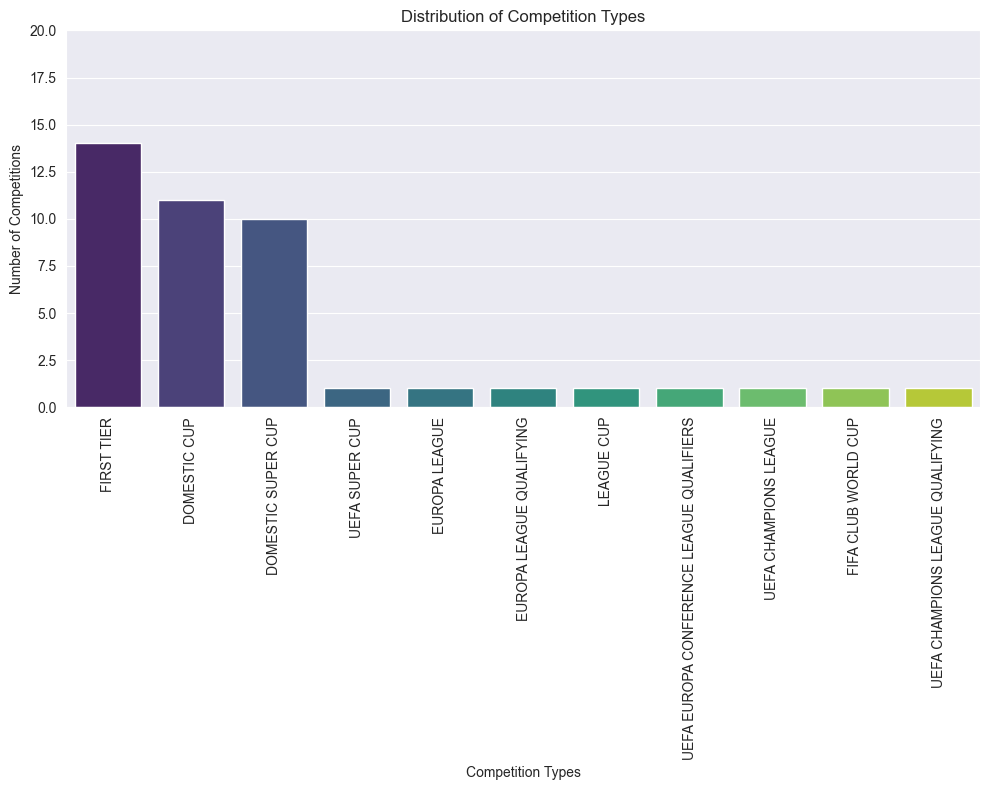

In [209]:
competition_types = df['sub_type'].value_counts()

# Create a bar plot
plt.figure(figsize=(10, 8))
bar_plot = sns.barplot(x=competition_types.index, y=competition_types.values, hue=competition_types.index, palette='viridis', legend=False)

# Customize the plot
plt.title('Distribution of Competition Types')
plt.xlabel('Competition Types')
plt.ylabel('Number of Competitions')
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

# Set the y-axis limits to provide space for the text
plt.ylim(0, 20)  # Adjust as needed

plt.tight_layout()  # Adjust layout for better spacing
plt.show()

# Distribution of Competition Types

The bar plot presented here provides a comprehensive overview of the distribution of various competition types within the dataset. Each bar signifies the number of competitions associated with specific categories, such as domestic cups, league cups, and international tournaments. 

This visualization is crucial as it highlights the prevalence of different competition types in the context of football leagues and tournaments, allowing us to understand their relative importance. For instance, the dominance of the "First Tier" competitions suggests a concentration of high-stakes matches. In contrast, the presence of "Domestic Cup" competitions indicates the significance of national tournaments in the football landscape.

Understanding this distribution is important for stakeholders, including club managers, analysts, and fans, as it provides insights into the competitive landscape of football. By analyzing the frequency and types of competitions, stakeholders can make informed decisions regarding player recruitment, strategic planning, and audience engagement.


In [210]:
df.to_csv('../cleaned_csv/competitions_cleaned.csv', index=False)